
#Reubicación de Estaciones de Servicio fuera de Zonas Escolares en Seattle, WA

Instalaciones que se requieren

In [3]:
!pip show pysal openpyxl geopandas pandas h3 geopy osmnx mapclassify

Name: pysal
Version: 25.7
Summary: Meta Package for PySAL - A library of spatial analysis functions
Home-page: 
Author: 
Author-email: Serge Rey <sjsrey@gmail.com>, Levi Wolf <levi.john.wolf@gmail.com>
License: BSD 3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: access, beautifulsoup4, esda, geopandas, giddy, inequality, libpysal, mapclassify, mgwr, momepy, numpy, packaging, pandas, platformdirs, pointpats, requests, scikit-learn, scipy, segregation, shapely, spaghetti, spglm, spint, splot, spopt, spreg, tobler
Required-by: 
---
Name: openpyxl
Version: 3.1.5
Summary: A Python library to read/write Excel 2010 xlsx/xlsm files
Home-page: https://openpyxl.readthedocs.io
Author: See AUTHORS
Author-email: charlie.clark@clark-consulting.eu
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: et-xmlfile
Required-by: 
---
Name: geopandas
Version: 1.2.0
Summary: Geographic pandas extensions
Home-page: 
Author: 
Author-email: Kelsey Jordahl <kjordahl@alum.

In [4]:
!pip install osmnx mapclassify

#DATOS PARA PROCESAR

In [5]:
# Se importa la librería geopandas para el análisis de datos espaciales
import geopandas as gpd

# Se define la URL del archivo shapefile alojado en GitHub
filez = "https://raw.githubusercontent.com/a20243018-del/CAVS/main/tract20_king_county.shp"

# Se lee el archivo de mapa espacial y se almacena en la variable seattle
seattle = gpd.read_file(filez)

# Se muestra la información general de la estructura y columnas del mapa
seattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


Como podemos ver, al disolver los límites censales nos quedamos únicamente con la geometría general de Seattle:

In [8]:
# Se visualiza la tabla resultante para verificar el registro consolidado
seattle

,geometry,GEOID20,GROSS_ACRE,LAND_ACRES,WATER_ACRE,NAME,TRACT_NUMB,BASENAME,UVDA_AREA,CRA_NO,CRA_GRP,GEN_ALIAS,DETL_NAMES,C_DISTRICT
0,"MULTIPOLYGON (((1260535.89 188253.83, 1260523....",53033000402,444.493643,444.527261,0.0,Census Tract 4.02,402,4.02,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5


In [52]:
# Se consulta el Sistema de Referencia de Coordenadas (CRS) del mapa de Seattle
seattle.crs
# Definimos el CRS de Seattle en metros (UTM Zona 10N)
Seattle_crs = "EPSG:32610"

# Reproyectamos el mapa base a metros
seattle = seattle.to_crs(Seattle_crs)

Preprocesamiento de datos colaborativos (Crowdsourced)
Ahora necesitamos las escuelas y las estaciones de gasolina. Vamos a utilizar la API de OpenStreetMap para Python (osmnx), la cual nos facilita bastante obtener esta información.

Podemos descargar las estaciones de gasolina de Seattle de la siguiente manera:

In [53]:
# Se obtiene la ubicación de las estaciones de servicio en Seattle desde OpenStreetMap
import osmnx as ox

stations = ox.features_from_place("Seattle, Washington, USA",
                                  tags={'amenity': 'fuel'})

Como podemos observar, obtenemos las estaciones de gasolina organizadas directamente dentro de un GeoDataFrame:

In [54]:
# Se muestra la información general del GeoDataFrame de estaciones de gasolina
stations.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

OpenStreetMap nos entrega las estaciones sin proyectar:

In [55]:
# Se verifica el Sistema de Referencia de Coordenadas (CRS) de las estaciones descargadas
stations.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Notemos que la tabla cuenta con un índice múltiple (multi-index):

In [56]:
# Se visualiza la tabla de datos de estaciones de gasolina de Seattle para observar su estructura e índice
stations

geometry amenity  \
element id                                                                      
node    457773031                         POINT (-122.39997 47.63939)    fuel   
        631386821                          POINT (-122.3203 47.62518)    fuel   
        771801423                         POINT (-122.35525 47.73205)    fuel   
        1197964284                        POINT (-122.32958 47.58001)    fuel   
        1489962206                        POINT (-122.32805 47.66483)    fuel   
...                                                               ...     ...   
way     684913608   POLYGON ((-122.37612 47.5448, -122.37623 47.54...    fuel   
        727276570   POLYGON ((-122.33603 47.53219, -122.33603 47.5...    fuel   
        940949039   POLYGON ((-122.26383 47.68144, -122.26394 47.6...    fuel   
        1106778201  POLYGON ((-122.30916 47.57672, -122.30956 47.5...    fuel   
        1460417274  POLYGON ((-122.29762 47.5779, -122.29746 47.57...    fuel   

                       brand brand:wikidata                          name  \
element id                                                                  
node    457773031    Chevron        Q319642              Magnolia Chevron   
        631386821         76       Q1658320                            76   
        771801423    Chevron        Q319642                       Chevron   
        1197964284     Shell     Q110716465                         Shell   
        1489962206  7-Eleven        Q259340                      7-Eleven   
...                      ...            ...                           ...   
way     684913608        NaN            NaN  Gasco & South Seattle Market   
        727276570      Shell     Q110716465                       Shree's   
        940949039   7-Eleven        Q259340                      7-Eleven   
        1106778201  Sinclair            NaN                           NaN   
        1460417274      Arco        Q304769                          Arco   

                   addr:city addr:housenumber addr:postcode  \
element id                                                    
node    457773031        NaN              NaN           NaN   
        631386821    Seattle              915         98102   
        771801423        NaN              NaN           NaN   
        1197964284       NaN              NaN           NaN   
        1489962206       NaN              NaN           NaN   
...                      ...              ...           ...   
way     684913608        NaN              NaN           NaN   
        727276570    Seattle              140         98106   
        940949039        NaN              NaN           NaN   
        1106778201       NaN              NaN           NaN   
        1460417274       NaN              NaN           NaN   

                                addr:street  check_date  ... start_date  \
element id                                               ...              
node    457773031                       NaN         NaN  ...        NaN   
        631386821           East Roy Street  2024-08-13  ...        NaN   
        771801423                       NaN         NaN  ...        NaN   
        1197964284                      NaN         NaN  ...        NaN   
        1489962206                      NaN  2026-02-18  ...        NaN   
...                                     ...         ...  ...        ...   
way     684913608                       NaN         NaN  ...        NaN   
        727276570   Southwest Kenyon Street         NaN  ...        NaN   
        940949039                       NaN         NaN  ...        NaN   
        1106778201                      NaN         NaN  ...        NaN   
        1460417274                      NaN         NaN  ...        NaN   

                   fuel:e85 maxheight contact:facebook contact:instagram  \
element id                                                                 
node    457773031       NaN       NaN              NaN   

En el índice múltiple podemos observar los nodos (nodes), relaciones (relations) y caminos (ways):

In [57]:
# Se inspeccionan los valores del índice múltiple del GeoDataFrame de estaciones de Seattle
stations.index

MultiIndex([('node',  457773031),
            ('node',  631386821),
            ('node',  771801423),
            ('node', 1197964284),
            ('node', 1489962206),
            ('node', 2266423106),
            ('node', 2702032640),
            ('node', 2702054487),
            ('node', 2995124967),
            ('node', 5283345524),
            ...
            ( 'way',  600101678),
            ( 'way',  600101691),
            ( 'way',  600101760),
            ( 'way',  603557992),
            ( 'way',  616232144),
            ( 'way',  684913608),
            ( 'way',  727276570),
            ( 'way',  940949039),
            ( 'way', 1106778201),
            ( 'way', 1460417274)],
           names=['element', 'id'], length=128)

Esto devolverá los índices actuales a la tabla de datos y aparecerá una numeración de filas común:

In [58]:
# Se restablece el índice para pasar 'element' e 'id' a columnas y generar una numeración consecutiva
stations.reset_index(drop=False, inplace=True)

# Se muestran los primeros cinco registros para verificar el reajuste
stations.head()

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source
0,node,457773031,POINT (-122.39997 47.63939),fuel,Chevron,Q319642,Magnolia Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,node,631386821,POINT (-122.3203 47.62518),fuel,76,Q1658320,76,Seattle,915,98102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,node,771801423,POINT (-122.35525 47.73205),fuel,Chevron,Q319642,Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,node,1197964284,POINT (-122.32958 47.58001),fuel,Shell,Q110716465,Shell,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,node,1489962206,POINT (-122.32805 47.66483),fuel,7-Eleven,Q259340,7-Eleven,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Conservamos solo algunas columnas:

In [59]:
# Se seleccionan las columnas clave y se genera una copia limpia de la tabla
colsToKeep = ['element', 'name', 'geometry']
fuelSeattle = stations[colsToKeep].copy()



Reproyectamos los datos:

In [60]:
# Se reproyectan las estaciones al sistema de coordenadas proyectado (en metros) de Seattle
Seattle_crs = seattle.crs
fuelSeattle = fuelSeattle.to_crs(Seattle_crs)

Revisamos la estructura de los datos:

In [63]:
# Se comprueba el estado de las columnas y el total de registros en la nueva tabla
fuelSeattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   element   128 non-null    object  
 1   name      128 non-null    object  
 2   geometry  128 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 3.1+ KB


Como observamos arriba, la columna name de las estaciones tiene valores nulos. Debemos renombrar esos valores faltantes:

In [64]:
# Se reemplazan los valores faltantes en la columna 'name' por la etiqueta 'Unknown'
fuelSeattle.fillna({'name': 'Unknown'}, inplace=True)

Normalmente usamos los nombres como índice de las filas, pero estos no deberían estar duplicados. Como varios nombres se repiten (al ser 'Unknown'), debemos generar nombres únicos:

Asignamos los nuevos identificadores únicos como el índice definitivo de nuestro GeoDataFrame de estaciones de servicio:

In [65]:
# Se asigna la combinación del número de fila y nombre como índice oficial de la tabla
fuelSeattle.index = fuelSeattle.index.astype(str) + "_" + fuelSeattle.name

# Se muestran las primeras filas para verificar los nuevos índices aplicados
fuelSeattle.head()

,element,name,geometry
0_Magnolia Chevron,node,Magnolia Chevron,POINT (545070.577 5276395.041)
1_76,node,76,POINT (551068.412 5274865.552)
2_Chevron,node,Chevron,POINT (548343.649 5286720.849)
3_Shell,node,Shell,POINT (550414.847 5269839.108)
4_7-Eleven,node,7-Eleven,POINT (550448.153 5279266.856)


CONTINUANDO

In [66]:
# Se crea la columna 'newname' combinando la posición del índice con el nombre de la estación
fuelSeattle['newname'] = fuelSeattle.index.astype(str) + "_" + fuelSeattle.name

# Se establece 'newname' como el índice oficial del GeoDataFrame
fuelSeattle.set_index('newname', inplace=True)

# Se remueve la columna 'name' original para evitar redundancia
fuelSeattle.drop(columns=['name'], inplace=True)

# Se muestran los primeros registros de la tabla actualizada
fuelSeattle.head()

,element,geometry
newname,,
0_Magnolia Chevron_Magnolia Chevron,node,POINT (545070.577 5276395.041)
1_76_76,node,POINT (551068.412 5274865.552)
2_Chevron_Chevron,node,POINT (548343.649 5286720.849)
3_Shell_Shell,node,POINT (550414.847 5269839.108)
4_7-Eleven_7-Eleven,node,POINT (550448.153 5279266.856)


Observemos que los nodos (nodes) son puntos, los caminos (ways) son líneas o formas simples construidas a partir de puntos, y las relaciones (relations) son contenedores conceptuales que agrupan cualquiera de los otros elementos para representar características complejas.

Comparemos con las geometrías disponibles:

In [67]:
# Se importa pandas para generar tablas estadísticas cruzadas
import pandas as pd

# Se realiza una tabulación cruzada entre el tipo de elemento OSM y el tipo de geometría
pd.crosstab(fuelSeattle.element, fuelSeattle.geometry.geom_type, margins=True)

col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


Este es el elemento de tipo 'way' que tenemos (geometría de polígono):

In [68]:
# Se filtran e inspeccionan las estaciones de gasolina en Seattle catalogadas como 'way'
stations[stations.element == 'way']

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source
17,way,34618474,"POLYGON ((-122.34485 47.69085, -122.34485 47.6...",fuel,Arco,Q304769,Arco,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,way,34618510,"POLYGON ((-122.34415 47.69005, -122.34415 47.6...",fuel,76,Q1658320,76,Seattle,8408,98103,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19,way,35965166,"POLYGON ((-122.34417 47.70536, -122.34417 47.7...",fuel,Arco,Q304769,Arco,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,way,92190405,"POLYGON ((-122.34462 47.7193, -122.34473 47.71...",fuel,76,Q1658320,76,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21,way,136051471,"POLYGON ((-122.38465 47.58105, -122.38465 47.5...",fuel,Safeway,Q1508234,Safeway,Seattle,4115,98116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,way,684913608,"POLYGON ((-122.37612 47.5448, -122.37623 47.54...",fuel,NaN,NaN,Gasco & South Seattle Market,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
124,way,727276570,"POLYGON ((-122.33603 47.53219, -122.33603 47.5...",fuel,Shell,Q110716465,Shree's,Seattle,140,98106,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125,way,940949039,"POLYGON ((-122.26383 47.68144, -122.26394 47.6...",fuel,7-Eleven,Q259340,7-Eleven,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MapWithAI
126,way,1106778201,"POLYGON ((-122.30916 47.57672, -122.30956 47.5...",fuel,Sinclair,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Graficamos la forma del polígono de la estación:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

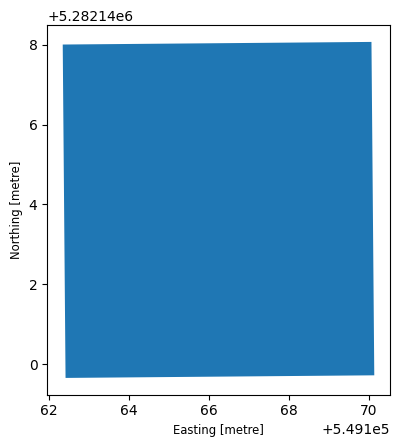

In [69]:
# Se grafica la primera estación de tipo 'way' para visualizar su forma de polígono
fuelSeattle[fuelSeattle.element == 'way'].iloc[[0]].plot()

Obtengamos las escuelas:

In [70]:
# Se obtienen las escuelas ubicadas en Seattle desde OpenStreetMap
schools = ox.features_from_place("Seattle, Washington, USA",
                                  tags={'amenity': 'school'})

# Se muestra la información general del GeoDataFrame de escuelas
schools.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

Reformateemos estos datos tal como lo hicimos anteriormente:

In [71]:
# Se restablece el índice del GeoDataFrame de escuelas de Seattle
schools.reset_index(inplace=True)

# Se seleccionan únicamente las columnas relevantes y se genera una copia limpia
schoolSeattle = schools[['element', 'name', 'geometry']].copy()

# Se reemplazan los nombres faltantes por la etiqueta 'Unknown'
schoolSeattle.fillna({'name': 'Unknown'}, inplace=True)

# Se crea la columna 'newname' combinando la posición con el nombre de la escuela
schoolSeattle['newname'] = schoolSeattle.index.astype(str) + "_" + schoolSeattle.name

# Se define 'newname' como el índice principal de la tabla
schoolSeattle.set_index('newname', inplace=True)

# Se remueve la columna 'name' redundante
schoolSeattle.drop(columns=['name'], inplace=True)

# Se reproyecta el mapa de escuelas al sistema proyectado en metros de Seattle
schoolSeattle = schoolSeattle.to_crs(Seattle_crs)

# Se visualizan los primeros cinco registros formateados
schoolSeattle.head()

,element,geometry
newname,,
0_Mapleleaf School,node,POINT (552925.436 5283350.335)
1_Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2_Epic Life Academy,node,POINT (549394.116 5283758.769)
3_Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4_Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)


Observemos la relación entre el tipo de elemento y la geometría:

In [72]:
# Se realiza una tabulación cruzada entre el tipo de elemento de OSM y la geometría resultante
pd.crosstab(schoolSeattle.element, schoolSeattle.geometry.geom_type, margins=True)

col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


Estos son los datos originales para elementos de tipo 'relation' con geometría 'MultiPolygon':

In [73]:
# Se filtran las escuelas originales catalogadas como 'relation' y 'MultiPolygon'
schools[(schools.element == 'relation') & (schools.geometry.geom_type == 'MultiPolygon')]

,element,id,geometry,amenity,check_date,ele,gnis:feature_id,name,addr:city,addr:housenumber,...,building:levels,fax,short_name,start_date,addr:housename,nursery,preschool,school:language,layer,type
54,relation,537423,"MULTIPOLYGON (((-122.2931 47.57649, -122.29298...",school,NaN,28,1505026,Franklin High School,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
56,relation,4764405,"MULTIPOLYGON (((-122.31777 47.64223, -122.3176...",school,NaN,62,1515690,Seattle Preparatory School,Seattle,2400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
57,relation,7616973,"MULTIPOLYGON (((-122.33765 47.69496, -122.3376...",school,NaN,NaN,NaN,Cascadia Elementary School,Seattle,1700,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
59,relation,18609000,"MULTIPOLYGON (((-122.26364 47.67391, -122.2636...",school,NaN,NaN,NaN,Sand Point Elementary School,Seattle,6208,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon


Graficamos la geometría de las escuelas que son relaciones complejas (MultiPolygon):

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

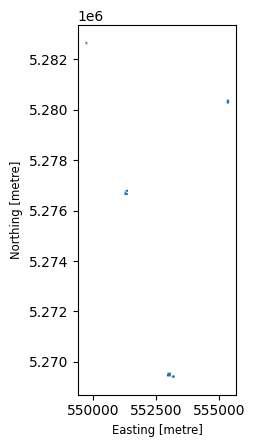

In [74]:
# Se grafica la geometría de las escuelas clasificadas como 'relation' y 'MultiPolygon'
schoolSeattle[(schoolSeattle.element == 'relation') & (schoolSeattle.geometry.geom_type == 'MultiPolygon')].plot()

Generamos el mapa interactivo de Seattle integrando las capas de la ciudad, escuelas y estaciones de servicio:

In [75]:
# Se crea el mapa base interactivo de Seattle utilizando los azulejos de OpenTopoMap
base = seattle.explore(
    tiles='OpenTopoMap',
    attr='Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)',
    color='lightblue'
)

# Se superpone la capa interactiva de las escuelas de Seattle en color negro
schoolSeattle.explore(m=base, color='black')

# Se superpone la capa interactiva de las estaciones de servicio en color rojo
fuelSeattle.explore(m=base, color='red')

# Se despliega el mapa interactivo completo
base

#Explorar la proximidad
Calculemos un par de matrices de distancia:

La distancia entre estaciones de servicio:

In [76]:
# Se calcula la matriz de distancias en metros entre todas las estaciones de gasolina de Seattle
D_Matrix_fuel_fuel = fuelSeattle.geometry.apply(
    lambda station: fuelSeattle.geometry.distance(station)
)

# Se muestra la matriz de distancias resultante
D_Matrix_fuel_fuel

newname,0_Magnolia Chevron_Magnolia Chevron,1_76_76,2_Chevron_Chevron,3_Shell_Shell,4_7-Eleven_7-Eleven,5_7-Eleven_7-Eleven,6_Morrison's North Star Marine_Morrison's North Star Marine,7_Shilshole Fuel Dock_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel_Dr. Dan's Biodiesel,9_76_76,...,118_Chevron_Chevron,119_76_76,120_Chevron_Chevron,121_Safeway Fuel Station_Safeway Fuel Station,122_Shell_Shell,123_Gasco & South Seattle Market_Gasco & South Seattle Market,124_Shree's_Shree's,125_7-Eleven_7-Eleven,126_Unknown_Unknown,127_Arco_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron_Magnolia Chevron,0.000000,6189.778099,10832.142979,8458.219249,6096.362935,3911.871820,4154.629544,4607.185893,3684.919842,6799.259673,...,11032.720301,8059.083730,8471.490011,11342.071122,8388.488702,10650.766388,12839.472695,11229.479609,9704.676294,10259.885224
1_76_76,6189.778099,0.000000,12164.390410,5068.756372,4444.794018,7396.837510,2913.822486,9025.058016,5776.876534,2146.281615,...,10502.171854,9283.591945,5828.349523,6582.987118,3490.937461,9859.853435,10391.001557,7544.714281,5423.572544,5486.468930
2_Chevron_Chevron,10832.142979,12164.390410,0.000000,17008.322965,7745.382606,6939.794167,9680.781667,6982.575734,7498.129000,14199.195661,...,3434.731016,2961.691541,7436.375075,18706.121900,15655.292108,20857.745520,22251.515513,8863.786937,17578.604974,17632.751402
3_Shell_Shell,8458.219249,5068.756372,17008.322965,0.000000,9427.806838,11287.548358,7342.660400,12635.016000,9933.327452,2922.512744,...,15557.714940,14059.287367,10879.733945,3206.070889,2163.657924,5243.026228,5325.665547,12298.163104,1528.265114,2402.851126
4_7-Eleven_7-Eleven,6096.362935,4444.794018,7745.382606,9427.806838,0.000000,4594.203464,2537.458079,6272.831613,3095.924539,6540.437675,...,6182.494529,4939.340577,2378.849213,10960.740771,7927.629559,13808.912707,14744.043923,5152.034055,9868.081904,9889.821437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market_Gasco & South Seattle Market,10650.766388,9859.853435,20857.745520,5243.026228,13808.912707,14330.734414,11384.887382,15256.296547,13384.622284,7840.707251,...,19975.906239,17895.800660,15622.732075,7048.807065,7406.644471,0.000000,3320.967459,17353.381510,6121.528764,6950.536820
124_Shree's_Shree's,12839.472695,10391.001557,22251.515513,5325.665547,14744.043923,16185.514303,12571.965336,17343.197545,14990.551645,8245.361423,...,20883.253836,19286.809328,16183.027772,5393.694936,7165.874001,3320.967459,0.000000,17427.534450,5304.377123,5824.618469
125_7-Eleven_7-Eleven,11229.479609,7544.714281,8863.786937,12298.163104,5152.034055,9340.534273,7314.479491,10839.148958,8108.038042,9514.437711,...,5617.194131,7342.966295,2828.590101,12564.668105,10253.850567,17353.381510,17427.534450,0.000000,12100.385190,11735.314154


A partir de esto, podemos calcular la distancia mínima entre esas estaciones de servicio:

In [77]:
# Se reemplazan los ceros por None para ignorar la distancia de una estación consigo misma
D_Matrix_fuel_fuel.replace(0, None, inplace=True)

# Se identifica la distancia a la estación más cercana, se ordenan los resultados y se muestran los 10 menores
D_Matrix_fuel_fuel.min(axis=1).sort_values().head(10)

,0
newname,
104_ARCO_ARCO,3.577986
103_ARCO_ARCO,3.577986
89_76_76,4.467367
88_76_76,4.467367
30_Chevron_Chevron,9.231022
11_Chevron_Chevron,9.231022
91_Shell_Shell,10.521046
90_Shell_Shell,10.521046
60_Pacific Pride_Pacific Pride,12.428133


La distancia entre estaciones de servicio y escuelas:

In [78]:
# Se calcula la matriz de distancias en metros entre las estaciones de gasolina y las escuelas de Seattle
D_Matrix_fuel_school = fuelSeattle.geometry.apply(
    lambda station: schoolSeattle.geometry.distance(station)
)

# Se despliega la matriz de distancias entre estaciones y escuelas
D_Matrix_fuel_school

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron_Magnolia Chevron,10491.659688,7199.084975,8539.173303,8956.657111,8932.523151,13341.958719,13507.709663,9506.260725,4487.653029,5324.737909,...,13761.296382,9053.687052,7195.602311,14410.390399,12230.115714,3124.787461,13580.295215,4054.694024,10282.565861,10565.424327
1_76_76,8685.624613,5789.863861,9049.451299,10124.534305,5853.770242,8808.620825,11975.722628,6599.617370,5074.222149,880.126226,...,9194.797832,6402.592462,6089.745057,10238.137431,10878.978200,3673.708903,12398.535914,2554.619356,8612.096410,6727.699624
2_Chevron_Chevron,5687.981663,6575.805111,3142.833012,2065.133147,7921.183151,20929.652730,23474.696332,7563.706626,7465.701803,11654.725826,...,21301.486962,7045.990100,6198.145060,22392.998311,4983.299677,9477.043229,23725.977819,12427.156563,5446.866034,18854.337587
3_Shell_Shell,13742.500324,10822.941478,13957.036131,14944.971496,10856.827909,4930.152593,6965.257592,11596.129786,9605.655199,5388.607746,...,5347.980500,11437.825204,11106.714608,5956.588399,15939.807496,7649.546886,7450.088356,4780.314108,13675.664902,2107.909975
4_7-Eleven_7-Eleven,4776.163021,1449.933898,4613.922112,5731.776499,2844.708492,13184.453100,16181.746778,3413.989799,1921.307178,4045.349103,...,13557.409322,2975.949318,1688.226327,14650.612357,6843.922073,3022.474841,16531.995201,5311.494858,4626.744314,11169.644124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market_Gasco & South Seattle Market,18437.654830,15257.637660,18016.092365,18818.447391,15701.177153,7223.804112,2917.573907,16447.522259,13440.851728,9890.137026,...,7489.956010,16219.730566,15482.629187,7043.580298,20596.596877,11308.744575,2917.011727,8493.599402,18333.769196,5192.808772
124_Shree's_Shree's,19046.714482,16146.376840,19238.321146,20186.490665,16131.338043,4633.509651,2212.511637,16863.752907,14799.205507,10699.306284,...,4762.577365,16729.265592,16426.505984,3973.425033,21246.496324,12755.913237,2957.170911,9823.178035,18986.753055,3812.301432
125_7-Eleven_7-Eleven,3191.366019,4396.077208,6402.128582,7587.141782,2308.936140,14581.418422,19250.984757,1890.496999,6978.426106,7738.111508,...,14859.036606,2191.162884,4562.774267,16156.189878,4800.640849,8052.316222,19748.085148,9560.847169,3273.765496,13416.903822


#Decisión 1: Encontrar las estaciones que deberían eliminarse
Ahora, podemos calcular la distancia mínima desde una estación de servicio a una escuela y ordenar las estaciones por ese valor:

In [79]:
# Se calcula la distancia mínima desde cada estación a la escuela más cercana y se ordenan los 10 valores menores
D_Matrix_fuel_school.min(axis=1).sort_values().head(10)

,0
newname,
102_Shell_Shell,0.824760
38_Shell_Shell,23.258460
69_Shell_Shell,36.646314
1_76_76,75.072216
111_Space Age_Space Age,91.233431
74_Shell_Shell,94.493039
109_Shell_Shell,97.053490
96_Chevron_Chevron,100.324890
36_Chevron_Chevron,112.051912


In [80]:
# Se define el umbral de distancia mínima de seguridad en metros
minDist = 200

#Decisión 2: Perímetro de seguridad de cada escuela
Creemos el área de seguridad alrededor de cada escuela. Esto requiere aplicar un área de influencia (buffer):

In [81]:
# Se genera el área de amortiguamiento (buffer) alrededor de cada escuela en Seattle
schoolSeattle_buffered = schoolSeattle.buffer(minDist)

# Se visualiza el conjunto de geometrías resultantes con el perímetro de seguridad
schoolSeattle_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


En este bloque verificamos el tipo de objeto resultante al crear el área de amortiguamiento (buffer), lo convertimos de una GeoSeries a un GeoDataFrame completo y confirmamos que todas las geometrías generadas sean polígonos de seguridad.

In [82]:
# Se verifica el tipo de objeto generado al aplicar el buffer (GeoSeries)
type(schoolSeattle_buffered)

geopandas.geoseries.GeoSeries

Convirtiendo una GeoSeries en GeoDataFrame:

In [83]:
# Se convierte la GeoSeries de zonas amortiguadas en un GeoDataFrame
secured_schoolSeattle = gpd.GeoDataFrame(geometry=schoolSeattle_buffered)

# Se visualiza la tabla resultante con los perímetros de seguridad de las escuelas
secured_schoolSeattle

,geometry
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."



Los buffers crearon polígonos:

In [84]:
# Se contabiliza la frecuencia de los tipos de geometría generados en el GeoDataFrame
secured_schoolSeattle.geometry.geom_type.value_counts()

,count
Polygon,217


#Decisión 3: Estandarización de las geometrías de las estaciones de servicio
No todas las estaciones de servicio son puntos:

In [85]:
# Se contabiliza la cantidad de estaciones según su tipo de geometría (Point o Polygon)
fuelSeattle.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


El punto es una representación simple. Por lo tanto, crearemos un área de influencia (buffer) de 10 metros para cada estación con geometría de punto, asegurándonos de estandarizarlas como polígonos:

In [86]:
# Se crea una copia del GeoDataFrame original de estaciones de Seattle
fuelSeattle_allPoly = fuelSeattle.copy()

# Se aplica un buffer de 10 metros únicamente a las geometrías de tipo 'Point'
fuelSeattle_allPoly['geometry'] = [
    station.buffer(10) if station.geom_type == 'Point' else station
    for station in fuelSeattle.geometry
]

Reverificamos que todas las geometrías sean ahora polígonos:

In [87]:
# Se verifica que todas las geometrías hayan sido convertidas exitosamente a polígonos
fuelSeattle_allPoly.geometry.geom_type.value_counts()

,count
Polygon,128


#Decisión 4: Overlay o SJoin para determinar las estaciones de servicio en conflicto

In [88]:
# Se realiza una superposición (overlay) por intersección para obtener las áreas recortadas
fuelSeattle_allPoly.overlay(secured_schoolSeattle, how='intersection', keep_geom_type=False)

,element,geometry
0,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
1,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
2,node,"POLYGON ((550424.799 5269838.128, 550424.655 5..."
3,node,"POLYGON ((545961.026 5280205.552, 545960.882 5..."
4,node,"POLYGON ((553782.981 5266125.595, 553782.837 5..."
5,node,"POLYGON ((548171.127 5263444.827, 548170.983 5..."
6,way,"POLYGON ((549200.164 5283742.752, 549194.91 52..."
7,way,"POLYGON ((546272.901 5269904.828, 546264.427 5..."
8,way,"POLYGON ((552390.26 5272921.863, 552382.489 52..."
9,way,"POLYGON ((552390.26 5272921.863, 552382.489 52..."


In [89]:
# Se realiza una unión espacial (sjoin) conservando la geometría original de las estaciones
fuelSeattle_allPoly.sjoin(secured_schoolSeattle, how='inner', predicate='intersects')

,element,geometry,newname_right
newname_left,,,
1_76_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
3_Shell_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.808, 548171.127 5...",6_Learning Way School
19_Arco_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School


In [90]:
# Se obtienen las estaciones de servicio de Seattle que interceptan las zonas restringidas de las escuelas
gas_relocate = fuelSeattle_allPoly.sjoin(secured_schoolSeattle, how='inner', predicate='intersects')

Es posible que el índice tenga duplicados (si una misma estación está cerca de múltiples escuelas):

In [91]:
# Se verifica si existen filas duplicadas en el índice del resultado
is_duplicate = gas_relocate.index.duplicated(keep=False)
gas_relocate[is_duplicate]

,element,geometry,newname_right
newname_left,,,
1_76_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
25_Arco_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
25_Arco_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",187_Nova High School
69_Shell_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",198_Seattle World School
69_Shell_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",116_Morningside Academy
69_Shell_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",51_The Hatch School
72_7-Eleven_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",198_Seattle World School
72_7-Eleven_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",116_Morningside Academy


Recordemos que los nombres están en el índice de filas, por lo tanto:

In [92]:
# Se restablece el índice, se eliminan los registros repetidos y se asigna nuevamente el índice principal
gas_relocate = gas_relocate.reset_index(drop=False).\
    drop_duplicates(subset='newname_left').\
    set_index('newname_left')

# Se muestran los primeros registros de las estaciones que deben reubicarse
gas_relocate.head()

,element,geometry,newname_right
newname_left,,,
1_76_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
3_Shell_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.808, 548171.127 5...",6_Learning Way School


Aplicando el cambio definitivo:

In [93]:
# haciendo el cambio real
gas_relocate = gas_relocate.reset_index(drop=False).\
    drop_duplicates(subset='newname_left').\
    set_index('newname_left')

Veamos tanto las escuelas involucradas como aquellas estaciones que deben reubicarse:

In [94]:
# Se generan los perímetros de seguridad escolares afectados en amarillo
base = secured_schoolSeattle.sjoin(
    gas_relocate,
    how='inner',
    predicate='intersects'
).explore(
    color='yellow',
    tiles='OpenTopoMap',
    attr='Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)'
)

# Se superponen las estaciones de servicio a reubicar en color rojo
gas_relocate.explore(m=base, color='red')

# Se despliega el mapa interactivo
base

#Decisión 5: Encontrar lugares adecuados para las estaciones en conflicto
No podemos colocar las estaciones de servicio en cualquier lugar. Tienen que estar situadas a lo largo de rutas transitables, no dentro de viviendas o edificios.   Encontrar ubicaciones adecuadas a lo largo de las rutas.

Obtengamos la red vial de Seattle con la ayuda de OSM:

In [98]:
# Definir la ubicación de estudio
place = "Seattle, Washington, USA"

# Descargar el grafo de la red vial transitable (drive) para Seattle
G = ox.graph_from_place(place, network_type="drive")

# Convertir los bordes del grafo (las calles) en un GeoDataFrame
streets = ox.graph_to_gdfs(G, nodes=False, edges=True)

# Consultar la cantidad de tramos viales y columnas
streets.shape

(50301, 15)

obtuvimos un amplio conjunto de rutas

In [99]:
# Inspeccionar la estructura de los datos y los tipos de columna de las calles
streets.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


In [100]:
# Inspeccionar las categorías únicas de tipos de vía
streets.highway.value_counts().index

Index([                    'residential',                        'tertiary',
                             'secondary',                         'primary',
                          'unclassified',                   'motorway_link',
                                 'trunk',                        'motorway',
                          'primary_link',                  'secondary_link',
                         'tertiary_link',                   'living_street',
         ['unclassified', 'residential'],                      'trunk_link',
                                'busway',         ['tertiary', 'secondary'],
                ['primary', 'secondary'],  ['living_street', 'residential'],
           ['motorway', 'motorway_link'],     ['trunk_link', 'residential'],
             ['tertiary', 'residential'],        ['trunk_link', 'tertiary'],
            ['tertiary', 'unclassified'],      ['unclassified', 'tertiary'],
       ['secondary_link', 'residential'],    ['secondary_link', 'tertiary'],

In [101]:
# Definir los tipos de vía aptos para instalar estaciones de servicio
GAS_STATION_ROAD_TYPES = [
    'motorway',      # Vías de alta velocidad con acceso limitado
    'primary',       # Carreteras o avenidas principales
    'trunk',         # Rutas regionales importantes
    'motorway_link', # Rampas de acceso/salida de autopistas
    'primary_link',  # Conectores de vías principales
    'trunk_link',    # Conectores de rutas troncales
    ['motorway', 'trunk'],
    ['primary', 'motorway_link'],
    ['primary', 'primary_link']
]

# Filtrar únicamente las calles idóneas
suitable_roads = streets[streets.highway.isin(GAS_STATION_ROAD_TYPES)]

# Consultar la cantidad de tramos aptos obtenidos
suitable_roads.shape

(3709, 15)

Reproyectemos las rutas al CRS de Seattle:




In [102]:
suitable_roads = suitable_roads.to_crs(seattle.crs)

A continuación, necesitamos crear un buffer alrededor de las estaciones:

In [103]:
competitionDistance = 200  # un valor seguro a partir de 'D_Matrix_fuel_fuel'
fuelSeattle_allPoly_buffered = fuelSeattle_allPoly.buffer(competitionDistance)

TENEMOS UN GDF

In [104]:
type(fuelSeattle_allPoly_buffered)

geopandas.geoseries.GeoSeries

In [105]:
secured_fuelSeattle_allPoly = gpd.GeoDataFrame(geometry=fuelSeattle_allPoly_buffered)

Combinemos las zonas de seguridad:

In [106]:
secured_areas_dissolved = secured_fuelSeattle_allPoly.overlay(
    secured_schoolSeattle,
    how='union',
    keep_geom_type=False
).dissolve()

secured_areas = gpd.GeoDataFrame(geometry=secured_areas_dissolved.geometry)

Filtrar las rutas: NO podemos elegir una ubicación que se cruce con las zonas de seguridad.

¿Elegimos: overlay, sjoin o clip?

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

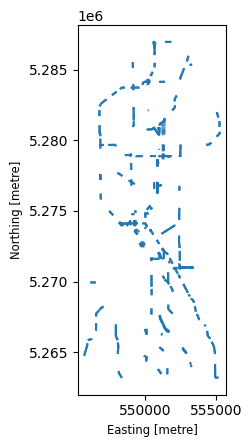

In [107]:
suitable_roads.clip(secured_areas, keep_geom_type=False).plot()

Aplicamos la resta espacial con overlay y el operador difference para obtener únicamente los tramos viales permitidos fuera de las zonas restringidas:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

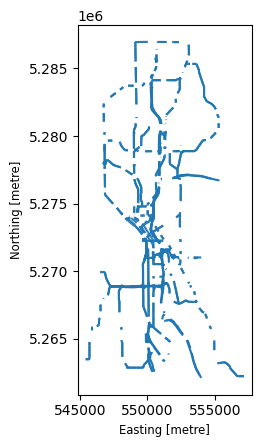

In [108]:
# Aplicar la resta espacial para aislar las rutas libres de restricciones
suitable_roads_clean = suitable_roads.overlay(
    secured_areas,
    keep_geom_type=False,
    how='difference'
)

# Visualizar la red vial resultante apta para la ubicación de estaciones
suitable_roads_clean.plot()

omparación con sjoin (Spatial Join) para evaluar intersecciones:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

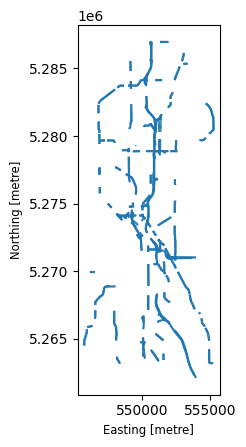

In [109]:
# Identificar segmentos viales que presentan alguna intersección con zonas prohibidas
suitable_roads.sjoin(secured_areas, predicate='intersects').plot()

Selección del método:
Seleccionamos overlay con how='difference' porque realiza una resta geométrica exacta: elimina únicamente los segmentos de carretera situados dentro de los 200 m restringidos (escuelas y estaciones de servicio) y conserva los tramos viales navegables seguros para la reubicación. (clip haría lo opuesto y sjoin descartaría calles enteras por un solo punto en contacto).

In [110]:
# Aplicar la resta espacial (difference) sobre las zonas restringidas y disolver geometrías contiguas
good_routes_forGas_dissolved = suitable_roads.overlay(
    secured_areas,
    keep_geom_type=False,
    how='difference'
).dissolve()

# Estructurar el resultado en un GeoDataFrame definitivo
good_routes_forGas = gpd.GeoDataFrame(geometry=good_routes_forGas_dissolved.geometry)

# Consultar la tabla de geometrías resultantes
good_routes_forGas

,geometry
0,"MULTILINESTRING ((551005.064 5276789.854, 5510..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

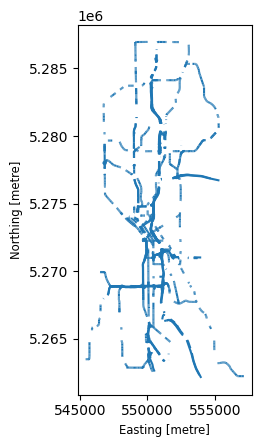

In [114]:
# Visualizar en el mapa estático la red vial apta para la reubicación
good_routes_forGas.plot()

Podemos elegir la ubicación de las nuevas estaciones de servicio a partir de las rutas permitidas:

In [125]:
import random

# Crear una copia de trabajo de las rutas viales aptas
potential_Locations = good_routes_forGas.copy()
newPOLYGONS = []
pointsComputed = 1
attempts = 1

while pointsComputed <= len(gas_relocate):
    # 1. Filtrar geometrías válidas existentes
    valid_locs = potential_Locations[~potential_Locations.is_empty & potential_Locations.geometry.notna()]
    if valid_locs.empty:
        break

    # 2. Seleccionar una ruta al azar e interpolar un punto (evita bugs de versión)
    row = valid_locs.sample(1).geometry.iloc[0]
    if 'Line' in row.geom_type:
        candidatePoint = row.interpolate(random.random(), normalized=True)
    else:
        candidatePoint = row.representative_point()

    # 3. Crear el buffer de 100m para la nueva estación candidata
    candidateStation = gpd.GeoDataFrame(
        geometry=[candidatePoint.buffer(100)],
        crs=potential_Locations.crs
    )

    # 4. Comprobar intersección con áreas restringidas
    if candidateStation.overlay(secured_areas, how='intersection', keep_geom_type=False).empty:
        newPOLYGONS.append(candidateStation)
        pointsComputed += 1
        # Restar el área ocupada por la nueva estación de las ubicaciones potenciales
        potential_Locations = potential_Locations.overlay(candidateStation, how='difference', keep_geom_type=False)

    if attempts > len(gas_relocate) * 10:
        break
    attempts += 1

# Mostrar número total de intentos y cantidad de nuevas estaciones generadas
attempts, len(newPOLYGONS)

(33, 26)

In [126]:
# Inspeccionar la lista de GeoDataFrames generados con las nuevas estaciones
newPOLYGONS

[                                            geometry
 0  POLYGON ((549902.725 5268891.778, 549902.244 5...,
                                             geometry
 0  POLYGON ((551250.558 5269443.031, 551250.076 5...,
                                             geometry
 0  POLYGON ((552419.6 5277030.535, 552419.118 527...,
                                             geometry
 0  POLYGON ((554290.669 5283529.143, 554290.187 5...,
                                             geometry
 0  POLYGON ((549919.39 5271024.143, 549918.908 52...,
                                             geometry
 0  POLYGON ((547566.782 5268859.463, 547566.3 526...,
                                             geometry
 0  POLYGON ((550154.622 5271357.535, 550154.141 5...,
                                             geometry
 0  POLYGON ((548164.651 5268883.011, 548164.17 52...,
                                             geometry
 0  POLYGON ((550384.22 5272509.194, 550383.738 52...,
                   

In [127]:
# Concatenar la lista de GeoDataFrames individuales en una sola estructura tabular
pd.concat(newPOLYGONS)

,geometry
0,"POLYGON ((549902.725 5268891.778, 549902.244 5..."
0,"POLYGON ((551250.558 5269443.031, 551250.076 5..."
0,"POLYGON ((552419.6 5277030.535, 552419.118 527..."
0,"POLYGON ((554290.669 5283529.143, 554290.187 5..."
0,"POLYGON ((549919.39 5271024.143, 549918.908 52..."
0,"POLYGON ((547566.782 5268859.463, 547566.3 526..."
0,"POLYGON ((550154.622 5271357.535, 550154.141 5..."
0,"POLYGON ((548164.651 5268883.011, 548164.17 52..."
0,"POLYGON ((550384.22 5272509.194, 550383.738 52..."
0,"POLYGON ((552201.381 5267682.216, 552200.899 5..."


In [128]:
# Guardar el GeoDataFrame concatenado con las áreas de amortiguamiento (buffers)
GoodLocationsGas_buffered_gdf = pd.concat(newPOLYGONS)

# Extraer el punto central (centroide) de cada área para definir la coordenada puntual exacta
GoodLocationsGas_gdf = gpd.GeoDataFrame(
    geometry=GoodLocationsGas_buffered_gdf.centroid
)

Visualización del mapa estático con las capas consolidadas del proyecto:

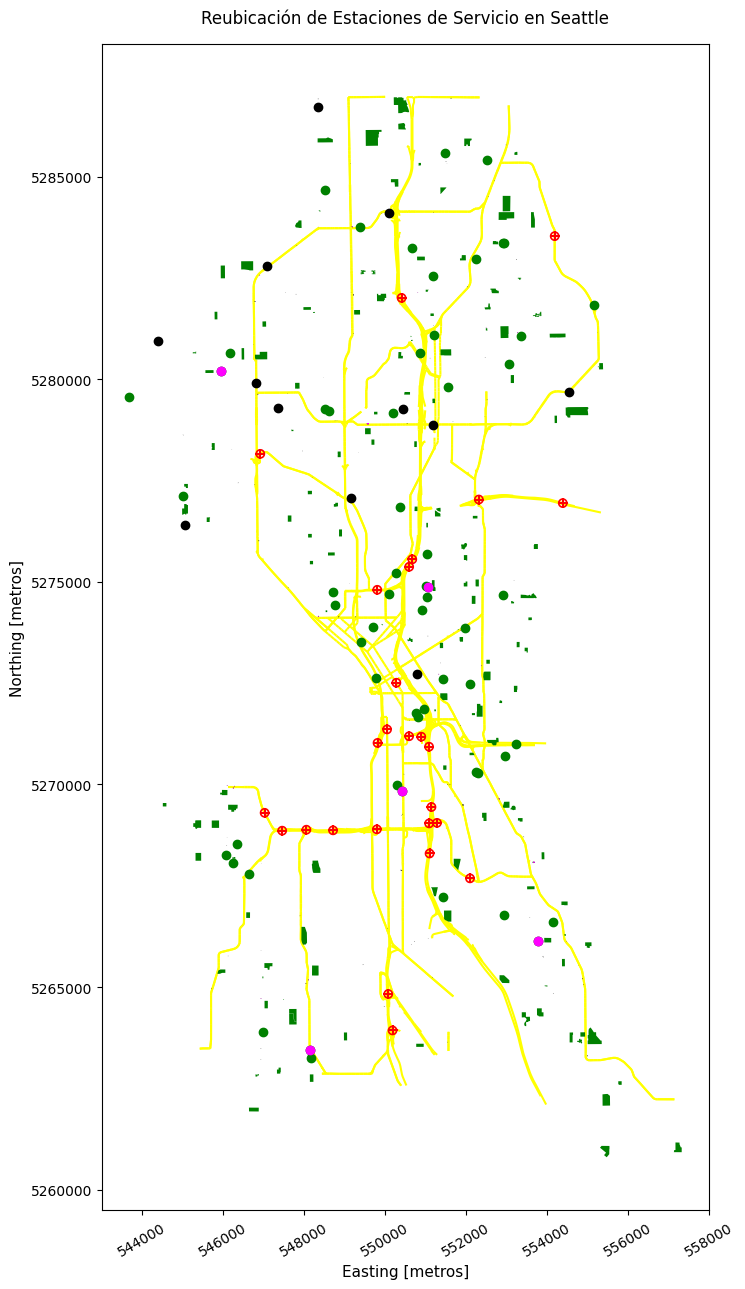

In [130]:
import matplotlib.pyplot as plt

# 1. Graficar la red vial apta original (capa base) ajustada a la escala de Seattle
base = suitable_roads.plot(color='yellow', figsize=(10, 13), zorder=1)

# 2. Graficar los círculos del buffer (100m) en borde rojo sin rellenar
GoodLocationsGas_buffered_gdf.plot(
    ax=base,
    edgecolor='red',
    facecolor='none',
    linewidth=1.2,
    zorder=2
)

# 3. Graficar la cruz roja en el centroide (queda exactamente dentro del círculo)
GoodLocationsGas_gdf.plot(
    ax=base,
    color='red',
    marker="+",
    markersize=60,
    zorder=3
)

# 4. Graficar todas las estaciones de servicio (negro) y escuelas (verde)
fuelSeattle.plot(ax=base, color='k', zorder=4)
schoolSeattle.plot(ax=base, color='green', zorder=5)

# 5. Destacar en magenta las estaciones reubicadas
fuelSeattle.clip(gas_relocate).plot(ax=base, color='magenta', zorder=5)

# --- FORMATO DE EJES Y MEJORA VISUAL ---
plt.ticklabel_format(useOffset=False, style='plain')  # Evitar notación científica o compresión
plt.xticks(rotation=30, fontsize=10)                  # Rotar números del eje X para evitar que se superpongan
plt.yticks(fontsize=10)
plt.xlabel("Easting [metros]", fontsize=11)
plt.ylabel("Northing [metros]", fontsize=11)
plt.title("Reubicación de Estaciones de Servicio en Seattle", fontsize=12, pad=15)

plt.tight_layout()  # Ajustar márgenes para una presentación limpia

Reverse geocoding
Obtengamos las direcciones físicas de las nuevas ubicaciones:

In [131]:
from geopy.geocoders import Nominatim
import time

# Inicializar el servicio de geocodificación con un user_agent personalizado para Seattle
geolocator = Nominatim(user_agent="seattle_gas_stations")

def get_address(point):
    # Extraer las coordenadas en formato (Longitud, Latitud)
    lon = point.x
    lat = point.y

    # Consultar la dirección física a partir de las coordenadas (Latitud, Longitud)
    location = geolocator.reverse((lat, lon), exactly_one=True, timeout=10)
    time.sleep(1)  # Pausa de 1 segundo para respetar las políticas de tasa de uso (Rate Limiting)

    if location:
        return location.address
    else:
        return None  # Dirección no encontrada

In [132]:
# Reproyectar los puntos a EPSG:4326 (grados decimales) para que geopy los reconozca
GoodLocationsGas_4326 = GoodLocationsGas_gdf.to_crs('EPSG:4326')

# Aplicar la función de geocodificación inversa a cada nueva ubicación
GoodLocationsGas_gdf['address'] = GoodLocationsGas_4326.geometry.apply(get_address)

In [133]:
# Mostrar la tabla final de resultados con las geometrías y sus direcciones en Seattle
GoodLocationsGas_gdf

,geometry,address
0,POINT (549802.725 5268891.778),"West Seattle Bridge, South Seattle, Seattle, K..."
0,POINT (551150.558 5269443.031),"I 5, Beacon Hill, Seattle, King County, Washin..."
0,POINT (552319.6 5277030.535),"SR 520, Montlake, Washington Park, University ..."
0,POINT (554190.669 5283529.143),"10305, Sand Point Way Northeast, Lavilla, Matt..."
0,POINT (549819.39 5271024.143),"Coast Guard Museum Northwest, 1519, Alaskan Wa..."
0,POINT (547466.782 5268859.463),"Southwest Spokane Street, West Seattle, Seattl..."
0,POINT (550054.622 5271357.535),"1018, 1st Avenue South, Yesler Terrace, Seattl..."
0,POINT (548064.651 5268883.011),"West Seattle Bridge, West Seattle, Seattle, Ki..."
0,POINT (550284.22 5272509.194),"701, 4th Avenue, West Edge, First Hill, Seattl..."
0,POINT (552101.381 5267682.216),"1776, South Columbian Way, Jefferson Park, Sou..."
